## Requerimientos Técnicos e Importación de Dependencias

In [3]:
# Carga e importación de dependencias
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    classification_report, 
    roc_auc_score
)

# Fijar semilla aleatoria para garantizar reproducibilidad exacta en laboratorio
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Entorno configurado correctamente. Semilla fijada en SEED =", SEED)


Entorno configurado correctamente. Semilla fijada en SEED = 42


### Paso 1: Configuración del Espacio de Características y Carga del Dataset Clínico

In [4]:
# Paso 1: Simulación estructurada de un dataset clínico de afecciones cardiacas (300 pacientes)
def generar_dataset_cardiaco(n_muestras=300, random_state=42):
    np.random.seed(random_state)
    
    # Generar características clínicas realistas
    edad = np.random.randint(30, 75, size=n_muestras)
    presion_sistolica = np.random.normal(130, 18, size=n_muestras).clip(90, 200)
    colesterol = np.random.normal(240, 45, size=n_muestras).clip(130, 400)
    frecuencia_max = np.random.normal(150, 22, size=n_muestras).clip(80, 202)
    angina_ejercicio = np.random.choice([0, 1], size=n_muestras, p=[0.65, 0.35])
    
    # Modelo generador subyacente con riesgo ponderado + ruido estocástico
    score_riesgo = (
        0.04 * (edad - 50) + 
        0.03 * (presion_sistolica - 120) + 
        0.02 * (colesterol - 200) - 
        0.03 * (frecuencia_max - 140) + 
        1.5 * angina_ejercicio + 
        np.random.normal(0, 1.0, size=n_muestras)
    )
    
    # Etiqueta binaria (1: Diagnóstico de Afección Cardiaca, 0: Sano)
    diagnostico = (score_riesgo > 0.5).astype(int)
    
    df = pd.DataFrame({
        'Edad': edad,
        'PresionSistolica': np.round(presion_sistolica, 1),
        'Colesterol': np.round(colesterol, 1),
        'FrecuenciaMax': np.round(frecuencia_max, 1),
        'AnginaEjercicio': angina_ejercicio,
        'DiagnosticoCardiopatia': diagnostico
    })
    return df

# Carga y vista previa
df_cardio = generar_dataset_cardiaco(n_muestras=300, random_state=SEED)
print(f"Dataset generado exitosamente: {df_cardio.shape[0]} pacientes, {df_cardio.shape[1]-1} características.")
df_cardio.head()


Dataset generado exitosamente: 300 pacientes, 5 características.


,Edad,PresionSistolica,Colesterol,FrecuenciaMax,AnginaEjercicio,DiagnosticoCardiopatia
0,68,137.6,241.3,178.3,1,1
1,58,146.9,283.6,173.4,0,1
2,44,114.4,196.2,140.0,1,0
3,72,132.6,243.6,163.9,0,1
4,37,105.3,308.6,116.4,0,1


### Paso 2: División Estratificada en Entrenador y Prueba (Train/Test Split)

In [5]:
# Paso 2: Separar características (X) de la variable objetivo (y) y dividir los conjuntos
X = df_cardio.drop(columns=['DiagnosticoCardiopatia'])
y = df_cardio['DiagnosticoCardiopatia']

# División 80% Entrenamiento y 20% Prueba con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=SEED, 
    stratify=y
)

print(f"Muestras de Entrenamiento: {X_train.shape[0]} pacientes | Muestras de Prueba: {X_test.shape[0]} pacientes")
print("Distribución de clases en entrenamiento (% Positivos):", f"{y_train.mean()*100:.1f}%")


Muestras de Entrenamiento: 240 pacientes | Muestras de Prueba: 60 pacientes
Distribución de clases en entrenamiento (% Positivos): 69.2%


### Paso 3: Inducción de Árboles de Decisión (Entropía y Ganancia de Información)

In [6]:
# Paso 3: Instanciar y entrenar un Árbol de Decisión sin restricciones iniciales (Ilimitado)
clf_arbol_completo = DecisionTreeClassifier(
    criterion='entropy', 
    random_state=SEED
)

# Entrenar el modelo induciendo las reglas a partir de D_train
clf_arbol_completo.fit(X_train, y_train)

# Evaluación preliminar de exactitud (Accuracy)
acc_train_comp = clf_arbol_completo.score(X_train, y_train)
acc_test_comp = clf_arbol_completo.score(X_test, y_test)

print(f"Exactitud en Entrenamiento (Árbol Completo): {acc_train_comp * 100:.2f}%")
print(f"Exactitud en Prueba (Árbol Completo)        : {acc_test_comp * 100:.2f}%")


Exactitud en Entrenamiento (Árbol Completo): 100.00%
Exactitud en Prueba (Árbol Completo)        : 76.67%


### Paso 4: Visualización del Árbol e Interpretación de Reglas Clínicas

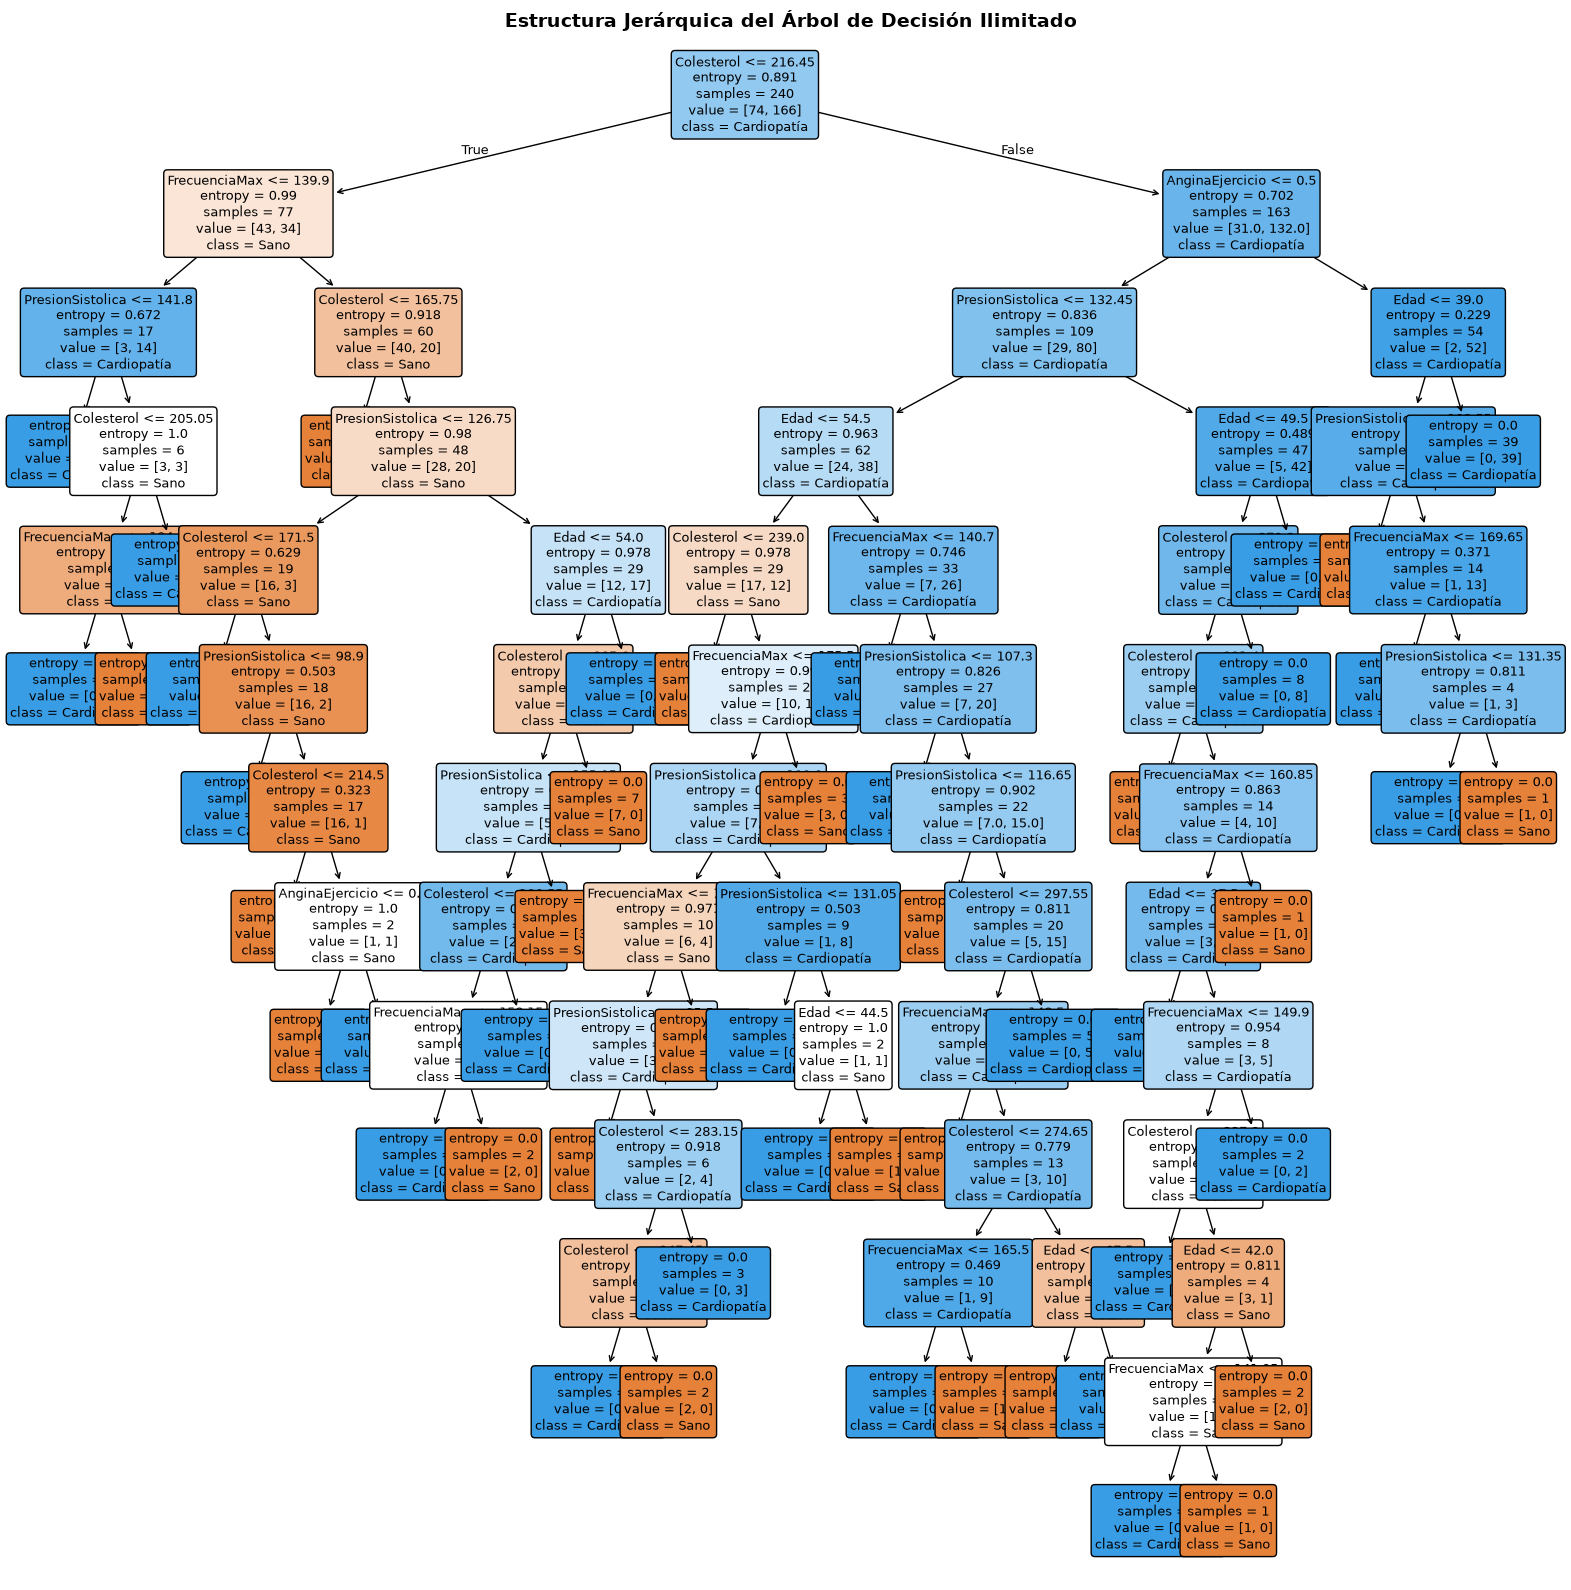

In [8]:
# Paso 4: Graficar la estructura jerárquica del árbol inducido
plt.figure(figsize=(16, 16))
plot_tree(
    clf_arbol_completo,
    feature_names=X.columns,
    class_names=['Sano', 'Cardiopatía'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Estructura Jerárquica del Árbol de Decisión Ilimitado", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### Paso 5: Diagnóstico de Sobreajuste (Overfitting) y Poda del Árbol (Pruning)

=== COMPARATIVA DE RENDIMIENTO: SOBREAJUSTE VS. REGULARIZACIÓN ===
Árbol Completo -> Train Accuracy: 100.0% | Test Accuracy: 76.7% (Brecha: 23.3%)
Árbol Podado   -> Train Accuracy: 77.5% | Test Accuracy: 81.7% (Brecha: -4.2%)


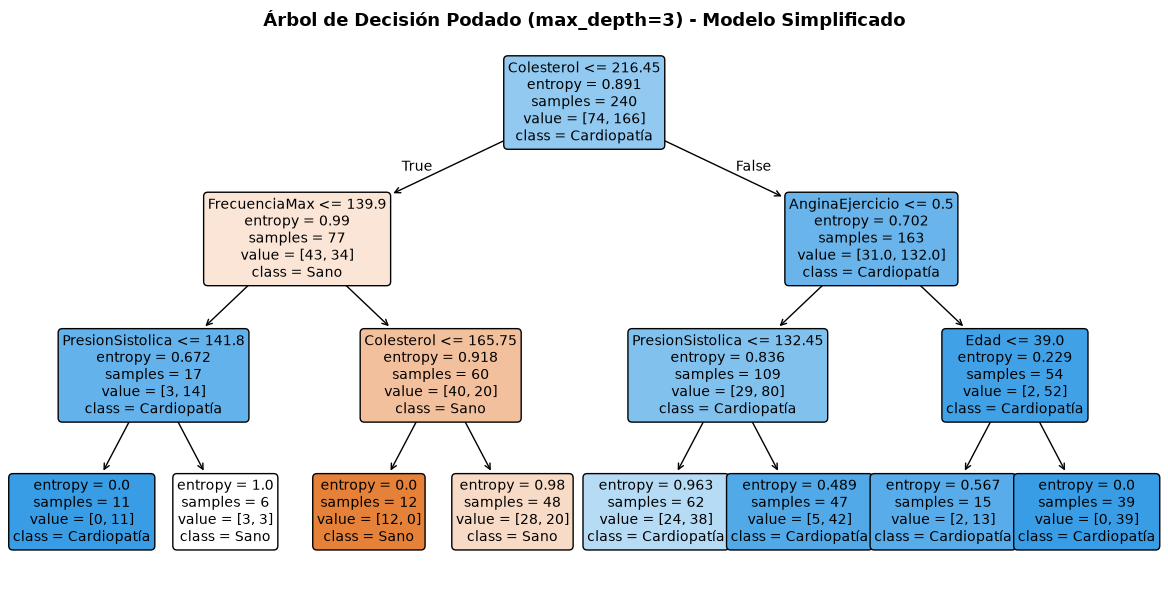

In [9]:
# Paso 5: Construir un Árbol Podado (Regularizado) para mejorar la generalización
clf_arbol_podado = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=3,                 # Restricción de profundidad máxima
    min_samples_leaf=5,          # Mínimo de pacientes requeridos por hoja
    random_state=SEED
)

clf_arbol_podado.fit(X_train, y_train)

acc_train_poda = clf_arbol_podado.score(X_train, y_train)
acc_test_poda = clf_arbol_podado.score(X_test, y_test)

print("=== COMPARATIVA DE RENDIMIENTO: SOBREAJUSTE VS. REGULARIZACIÓN ===")
print(f"Árbol Completo -> Train Accuracy: {acc_train_comp*100:.1f}% | Test Accuracy: {acc_test_comp*100:.1f}% (Brecha: {(acc_train_comp-acc_test_comp)*100:.1f}%)")
print(f"Árbol Podado   -> Train Accuracy: {acc_train_poda*100:.1f}% | Test Accuracy: {acc_test_poda*100:.1f}% (Brecha: {(acc_train_poda-acc_test_poda)*100:.1f}%)")

# Visualizar el árbol podado e interpretable
plt.figure(figsize=(12, 6))
plot_tree(
    clf_arbol_podado,
    feature_names=X.columns,
    class_names=['Sano', 'Cardiopatía'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árbol de Decisión Podado (max_depth=3) - Modelo Simplificado", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Paso 6: Evaluación Estadística con Matriz de Confusión y Métricas Clínicas

<Figure size 600x500 with 0 Axes>

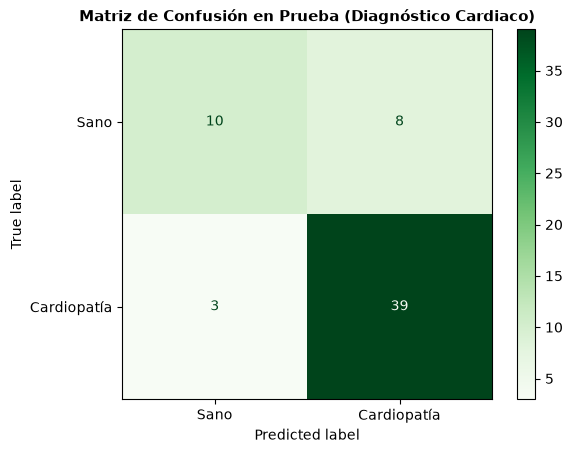

=== REPORTE DE CLASIFICACIÓN ESTADÍSTICA ===
                 precision    recall  f1-score   support

       Sano (0)       0.77      0.56      0.65        18
Cardiopatía (1)       0.83      0.93      0.88        42

       accuracy                           0.82        60
      macro avg       0.80      0.74      0.76        60
   weighted avg       0.81      0.82      0.81        60

Puntuación ROC-AUC: 0.8300


In [10]:
# Paso 6: Evaluación del modelo podado en el conjunto de prueba D_test
y_pred_poda = clf_arbol_podado.predict(X_test)
y_prob_poda = clf_arbol_podado.predict_proba(X_test)[:, 1]

# 1. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_poda)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sano', 'Cardiopatía'])

plt.figure(figsize=(6, 5))
disp.plot(cmap='Greens', values_format='d')
plt.title("Matriz de Confusión en Prueba (Diagnóstico Cardiaco)", fontsize=11, fontweight='bold')
plt.show()

# 2. Reporte de Clasificación Detallado
print("=== REPORTE DE CLASIFICACIÓN ESTADÍSTICA ===")
print(classification_report(y_test, y_pred_poda, target_names=['Sano (0)', 'Cardiopatía (1)']))

# 3. Área Bajo la Curva ROC (ROC-AUC)
auc_score = roc_auc_score(y_test, y_prob_poda)
print(f"Puntuación ROC-AUC: {auc_score:.4f}")


### # Paso 7: Validación Cruzada de 5 pliegues sobre la totalidad de las muestras

In [11]:
# Paso 7: Validación Cruzada de 5 pliegues sobre la totalidad de las muestras
scores_cv = cross_val_score(clf_arbol_podado, X, y, cv=5, scoring='f1')

print("=== VALIDACIÓN CRUZADA DE 5 PLIEGUES (MÉTRICA F1-SCORE) ===")
for fold, score in enumerate(scores_cv, 1):
    print(f"  Pliegue {fold}: F1-Score = {score:.4f}")

print(f"Rendimiento Promedio F1-Score: {scores_cv.mean():.4f} (+/- {scores_cv.std()*2:.4f})")


=== VALIDACIÓN CRUZADA DE 5 PLIEGUES (MÉTRICA F1-SCORE) ===
  Pliegue 1: F1-Score = 0.8211
  Pliegue 2: F1-Score = 0.8140
  Pliegue 3: F1-Score = 0.7407
  Pliegue 4: F1-Score = 0.8764
  Pliegue 5: F1-Score = 0.8506
Rendimiento Promedio F1-Score: 0.8205 (+/- 0.0914)
